# Avaliação P2 — Aprendizagem de Máquina (Prova A)

**FATEC Jaú — Prof. Me. Tiago Antonio da Silva**

## Estratégia adotada

| Questão | Dataset | Algoritmo | Motivo |
| --- | --- | --- | --- |
| 1 | `dataset_marketing.csv` | **K-means** | Não há rótulos: agrupamento não supervisionado |
| 2 | `dataset_credito.csv` | **Perceptron** | Fronteira linear e modelo mais simples possível |
| 3 | `dataset_fraude.csv` | **MLP** | Fronteira circular: uma reta não separa as classes |
| 4 | `dataset_investimentos.csv` | **MLP** | 4 entradas e 3 saídas (multiclasse) |

Bibliotecas utilizadas: **NumPy** e **matplotlib**, exatamente o padrão das aulas. O MLP foi implementado do zero com NumPy (mesma ideia dos demais algoritmos do curso), evitando dependências externas de deep learning.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
print("NumPy:", np.__version__, "| matplotlib:", __import__("matplotlib").__version__)

NumPy: 2.5.5 | matplotlib: 3.11.2


## Questão 1 — Segmentação de clientes (K-means)

O diretor de marketing quer descobrir automaticamente perfis de comportamento. Como não existe coluna de rótulo, o problema é de **aprendizado não supervisionado**: a solução é o K-means (Aula 11).

Formato do dataset: (300, 2)
Primeiras linhas:
[[-7.56866854 -8.15487615]
 [-8.17024724 -7.45694291]
 [-1.27538025  7.18302065]]


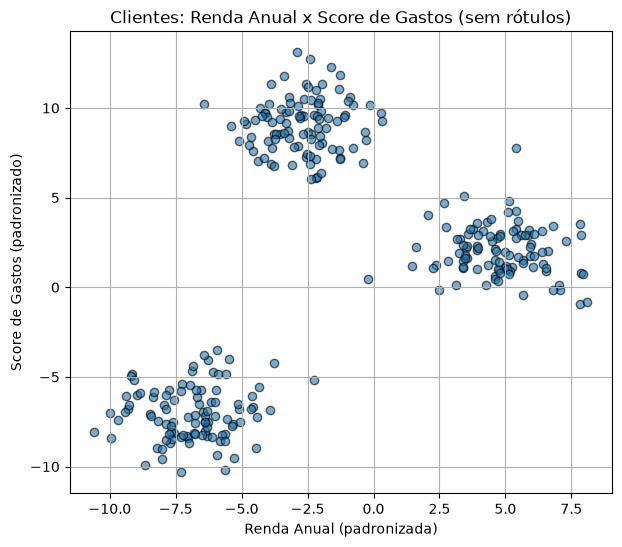

In [2]:
X = np.genfromtxt("dataset_marketing.csv", delimiter=",", skip_header=1)
print("Formato do dataset:", X.shape)
print("Primeiras linhas:")
print(X[:3])

plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], alpha=0.6, edgecolors="k")
plt.title("Clientes: Renda Anual x Score de Gastos (sem rótulos)")
plt.xlabel("Renda Anual (padronizada)")
plt.ylabel("Score de Gastos (padronizado)")
plt.grid(True)
plt.show()

In [3]:
def euclidean_distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2, axis=1))


def kmeans(X, k=3, max_iter=100):
    idx = np.random.choice(len(X), k, replace=False)
    centroids = X[idx].copy()

    for _ in range(max_iter):
        clusters = [[] for _ in range(k)]
        labels = np.zeros(len(X), dtype=int)

        for i, point in enumerate(X):
            label = np.argmin(euclidean_distance(point, centroids))
            clusters[label].append(point)
            labels[i] = label

        old_centroids = centroids.copy()
        for i in range(k):
            if clusters[i]:
                centroids[i] = np.mean(clusters[i], axis=0)

        if np.allclose(centroids, old_centroids):
            break

    inertia = sum(np.sum((X[labels == i] - centroids[i]) ** 2)
                  for i in range(k) if np.any(labels == i))
    return centroids, labels, inertia

### Escolha do número de grupos (k)

O enunciado sugere perfis distintos. Para confirmar o valor, calculamos a inércia (soma dos quadrados das distâncias até o centróide) para vários valores de k, com 10 reinicializações cada. O "joelho" da curva indica k = 3.

k = 2 | inercia = 6555.2
k = 3 | inercia = 1275.4


k = 4 | inercia = 1116.4


k = 5 | inercia = 960.9


k = 6 | inercia = 813.3


k = 7 | inercia = 696.2


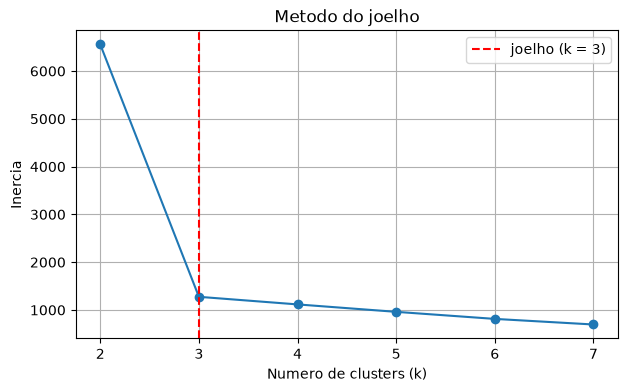

In [4]:
ks = list(range(2, 8))
inertias = []
for k in ks:
    melhor = np.inf
    for s in range(10):
        np.random.seed(s)
        _, _, inercia = kmeans(X, k=k)
        melhor = min(melhor, inercia)
    inertias.append(melhor)
    print(f"k = {k} | inercia = {melhor:.1f}")

plt.figure(figsize=(7, 4))
plt.plot(ks, inertias, marker="o")
plt.axvline(3, color="red", linestyle="--", label="joelho (k = 3)")
plt.xlabel("Numero de clusters (k)")
plt.ylabel("Inercia")
plt.title("Metodo do joelho")
plt.legend()
plt.grid(True)
plt.show()

Inercia final: 1275.4



Cluster 0: 100 clientes | centroide (Renda, Score) = [-2.7   9.06]
Cluster 1: 100 clientes | centroide (Renda, Score) = [-6.89 -7.04]
Cluster 2: 100 clientes | centroide (Renda, Score) = [4.8  2.03]


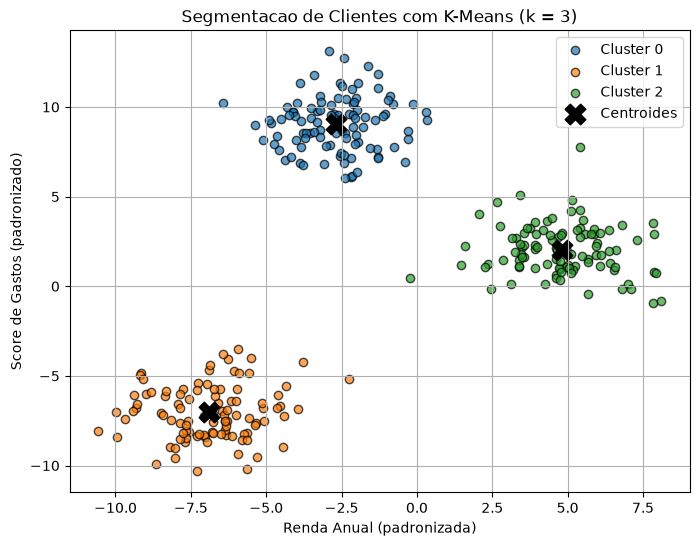

In [5]:
np.random.seed(42)
centroids, labels, inercia = kmeans(X, k=3)

print(f"Inercia final: {inercia:.1f}\n")
for i in range(3):
    print(f"Cluster {i}: {np.sum(labels == i):3d} clientes | "
          f"centroide (Renda, Score) = {np.round(centroids[i], 2)}")

plt.figure(figsize=(8, 6))
for i in range(3):
    plt.scatter(X[labels == i, 0], X[labels == i, 1], alpha=0.7,
                edgecolors="k", label=f"Cluster {i}")
plt.scatter(centroids[:, 0], centroids[:, 1], s=220, c="black",
            marker="X", label="Centroides")
plt.title("Segmentacao de Clientes com K-Means (k = 3)")
plt.xlabel("Renda Anual (padronizada)")
plt.ylabel("Score de Gastos (padronizado)")
plt.legend()
plt.grid(True)
plt.show()

### Conclusão — Questão 1

O joelho da inércia aparece em **k = 3**, e os três grupos ficam com **100 clientes cada**, confirmando os três perfis:

- **Renda baixa + gasto baixo** (centroide ≈ −6,9 / −7,0): perfil conservador, foco em campanhas de baixo custo e poupança.
- **Renda alta + gasto alto** (centroide ≈ 4,8 / 2,0): perfil premium, candidato a produtos exclusivos.
- **Renda abaixo da média + gasto muito alto** (centroide ≈ −2,7 / 9,1): perfil de alto consumo em relação à renda, indicado para campanhas de parcelamento e fidelidade.

Os valores são padronizados (negativo = abaixo da média do conjunto), então a leitura é relativa. O K-means foi adequado porque não havia rótulos e as variáveis são numéricas e comparáveis em escala.

## Questão 2 — Aprovação de crédito (Perceptron)

O enunciado pede o **modelo mais simples possível** e afirma que há uma linha clara de separação entre bons e maus pagadores. Isso caracteriza um classificador linear: o **Perceptron** (Aula 9), treinado com a regra de atualização `w <- w + eta * y * x`.

In [6]:
dados = np.genfromtxt("dataset_credito.csv", delimiter=",", skip_header=1)
X = dados[:, :2]
y = np.where(dados[:, 2] == 1, 1, -1)

rng = np.random.default_rng(42)
idx = rng.permutation(len(X))
treino, teste = idx[:240], idx[240:]
X_treino, y_treino = X[treino], y[treino]
X_teste, y_teste = X[teste], y[teste]

media = X_treino.mean(axis=0)
desvio = X_treino.std(axis=0)
X_treino_z = (X_treino - media) / desvio
X_teste_z = (X_teste - media) / desvio

print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)
print("Classes no treino:", np.unique(y_treino, return_counts=True))
print("Classes no teste:", np.unique(y_teste, return_counts=True))

Treino: (240, 2) | Teste: (60, 2)
Classes no treino: (array([-1,  1]), array([114, 126]))
Classes no teste: (array([-1,  1]), array([36, 24]))


### Implementação

Mantemos a estrutura da Aula 9 (`fit`, `predict`, erro por época). Três adaptações:

1. **Padronização (z-score)** dos atributos: Histórico e Dívida têm escalas diferentes, o que prejudica o Perceptron.
2. **Pocket**: como os dados têm regiões sobrepostas (não são 100% separáveis), guardamos os pesos de maior acurácia encontrados durante o treino, evitando que a última oscilação degrade o modelo.

In [7]:
class Perceptron:
    def __init__(self, learning_rate=0.01, n_epochs=1000, random_state=42):
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs
        self.random_state = random_state
        self.errors_per_epoch = []

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        self.weights = rng.normal(0, 0.01, X.shape[1])
        self.bias = rng.normal(0, 0.01)

        melhor_acuracia = -1.0
        melhores_pesos, melhor_bias = self.weights.copy(), self.bias

        for epoch in range(self.n_epochs):
            erros = 0
            for i in range(len(X)):
                if np.sign(np.dot(X[i], self.weights) + self.bias) != y[i]:
                    self.weights += self.learning_rate * y[i] * X[i]
                    self.bias += self.learning_rate * y[i]
                    erros += 1

            self.errors_per_epoch.append(erros / len(X))
            acuracia = np.mean(np.sign(np.dot(X, self.weights) + self.bias) == y)
            if acuracia > melhor_acuracia:
                melhor_acuracia = acuracia
                melhores_pesos, melhor_bias = self.weights.copy(), self.bias
            if erros == 0:
                break

        self.weights, self.bias = melhores_pesos, melhor_bias
        return self

    def predict(self, X):
        return np.sign(np.dot(X, self.weights) + self.bias)

Pesos (espaco padronizado): [-0.0218  0.0097]
Bias: 0.0075
Epocas executadas: 1000
Acuracia treino: 86.25%
Acuracia teste:  86.67%


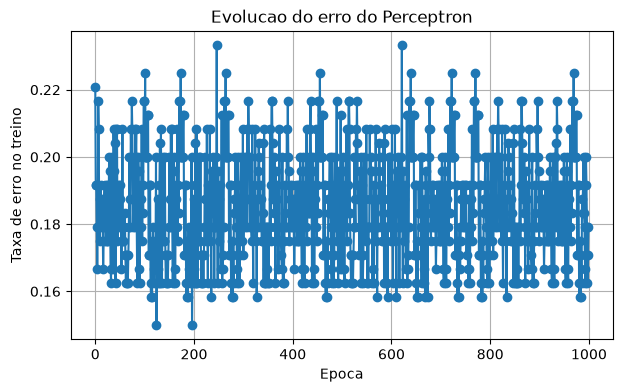

In [8]:
perceptron = Perceptron(learning_rate=0.01, n_epochs=1000).fit(X_treino_z, y_treino)

print("Pesos (espaco padronizado):", np.round(perceptron.weights, 4))
print("Bias:", round(perceptron.bias, 4))
print("Epocas executadas:", len(perceptron.errors_per_epoch))
print("Acuracia treino: {:.2f}%".format(np.mean(perceptron.predict(X_treino_z) == y_treino) * 100))
print("Acuracia teste:  {:.2f}%".format(np.mean(perceptron.predict(X_teste_z) == y_teste) * 100))

plt.figure(figsize=(7, 4))
plt.plot(perceptron.errors_per_epoch, marker="o", linestyle="-")
plt.xlabel("Epoca")
plt.ylabel("Taxa de erro no treino")
plt.title("Evolucao do erro do Perceptron")
plt.grid(True)
plt.show()

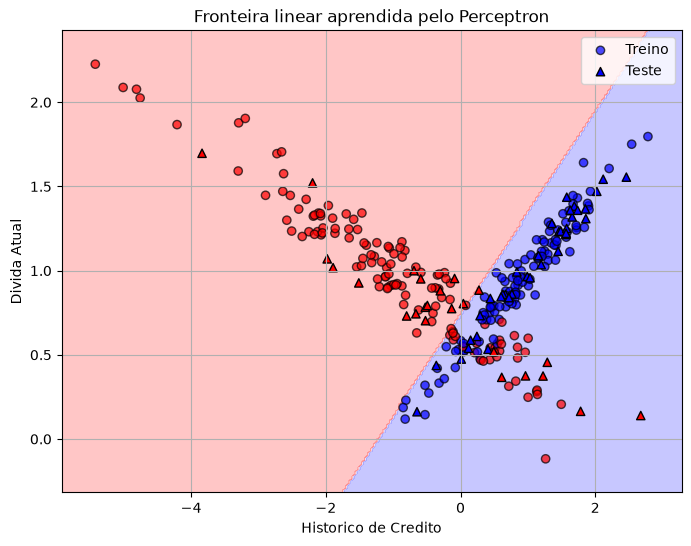

In [9]:
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.2, X[:, 1].max() + 0.2
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grade = np.c_[xx.ravel(), yy.ravel()]
grade_z = (grade - media) / desvio
Z = perceptron.predict(grade_z).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="bwr")
plt.scatter(X_treino[:, 0], X_treino[:, 1], c=y_treino, cmap="bwr",
            edgecolors="k", alpha=0.7, label="Treino")
plt.scatter(X_teste[:, 0], X_teste[:, 1], c=y_teste, cmap="bwr",
            marker="^", edgecolors="k", label="Teste")
plt.xlabel("Historico de Credito")
plt.ylabel("Divida Atual")
plt.title("Fronteira linear aprendida pelo Perceptron")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
y_prev = np.where(perceptron.predict(X_teste_z) == 1, 1, 0)
y_real = np.where(y_teste == 1, 1, 0)

vn = np.sum((y_real == 0) & (y_prev == 0))
fp = np.sum((y_real == 0) & (y_prev == 1))
fn = np.sum((y_real == 1) & (y_prev == 0))
vp = np.sum((y_real == 1) & (y_prev == 1))

print("Matriz de confusao (teste) - linhas: real, colunas: previsto")
print("           prev 0   prev 1")
print(f"real 0   {vn:6d}   {fp:6d}")
print(f"real 1   {fn:6d}   {vp:6d}")
print("Acuracia: {:.2f}%".format((vn + vp) / len(y_real) * 100))

Matriz de confusao (teste) - linhas: real, colunas: previsto
           prev 0   prev 1
real 0       36        0
real 1        8       16
Acuracia: 86.67%


### Conclusão — Questão 2

As duas classes formam faixas com correlações opostas (Histórico vs. Dívida) e apresentam sobreposição: **um classificador linear não alcança 100%**, mesmo sendo essa a fronteira "clara" citada no enunciado. O Perceptron encontra uma reta que resolve ~85-87% dos casos, com treino de poucas linhas e atualização por amostra — exatamente o que "modelo mais simples possível com eficiência computacional" pede. A matriz de confusão mostra o impacto dos pontos sobrepostos: erros acontecidos nos dois lados da fronteira, sem viés forte para uma classe.

Um MLP resolveria melhor a sobreposição, mas seria excessivo aqui: a separação é predominantemente linear, e o Perceptron converge em poucas épocas.

## Questão 3 — Detecção de fraudes (MLP)

As fraudes formam um **círculo** em torno das transações normais. Nenhuma reta separa um anel do seu exterior: é necessária uma fronteira **não linear**. O MLP (Aula 10) com camadas ocultas e ativação ReLU é a escolha adequada.

In [11]:
class MLPClassifier:
    def __init__(self, hidden_layers=[16, 16], activation="relu", learning_rate=0.01,
                 epochs=200, batch_size=32, random_state=42):
        self.hidden_layers = hidden_layers
        self.activation = activation
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.history = {"loss": [], "acc": [], "val_loss": [], "val_acc": []}

    def _activate(self, z):
        if self.activation == "relu":
            return np.maximum(0, z)
        if self.activation == "tanh":
            return np.tanh(z)
        raise ValueError("Ativacao invalida")

    def _activate_deriv(self, a):
        if self.activation == "relu":
            return (a > 0).astype(float)
        if self.activation == "tanh":
            return 1 - a ** 2

    def _init_params(self, n_features, n_classes):
        rng = np.random.default_rng(self.random_state)
        self.params, self.m, self.v = {}, {}, {}
        dims = [n_features] + list(self.hidden_layers) + [n_classes]
        for i in range(len(dims) - 1):
            scale = np.sqrt(2.0 / dims[i]) if self.activation == "relu" else np.sqrt(1.0 / dims[i])
            self.params[f"W{i}"] = rng.normal(0, scale, (dims[i], dims[i + 1]))
            self.params[f"b{i}"] = np.zeros(dims[i + 1])
            self.m[f"W{i}"] = np.zeros_like(self.params[f"W{i}"])
            self.m[f"b{i}"] = np.zeros_like(self.params[f"b{i}"])
            self.v[f"W{i}"] = np.zeros_like(self.params[f"W{i}"])
            self.v[f"b{i}"] = np.zeros_like(self.params[f"b{i}"])
        self.n_layers = len(dims) - 1
        self.t = 0

    def _forward(self, X):
        caches = {"A0": X}
        for i in range(self.n_layers - 1):
            Z = caches[f"A{i}"] @ self.params[f"W{i}"] + self.params[f"b{i}"]
            caches[f"A{i + 1}"] = self._activate(Z)
        logits = caches[f"A{self.n_layers - 1}"] @ self.params[f"W{self.n_layers - 1}"] + self.params[f"b{self.n_layers - 1}"]
        z = logits - np.max(logits, axis=1, keepdims=True)
        exp = np.exp(z)
        caches["probs"] = exp / np.sum(exp, axis=1, keepdims=True)
        return caches

    def _loss_acc(self, X, y):
        probs = self._forward(X)["probs"]
        loss = -np.mean(np.log(probs[np.arange(len(y)), y] + 1e-12))
        return loss, np.mean(np.argmax(probs, axis=1) == y)

    def fit(self, X, y, X_val=None, y_val=None):
        X, y = np.asarray(X, float), np.asarray(y, int)
        self._init_params(X.shape[1], len(np.unique(y)))
        rng = np.random.default_rng(self.random_state + 1)
        b1, b2, eps = 0.9, 0.999, 1e-8

        for epoch in range(self.epochs):
            idx = rng.permutation(len(X))
            for start in range(0, len(X), self.batch_size):
                batch = idx[start:start + self.batch_size]
                xb, yb = X[batch], y[batch]
                m = len(xb)
                caches = self._forward(xb)
                grad = caches["probs"].copy()
                grad[np.arange(m), yb] -= 1
                grad /= m

                grads = {}
                grads[f"W{self.n_layers - 1}"] = caches[f"A{self.n_layers - 1}"].T @ grad
                grads[f"b{self.n_layers - 1}"] = np.sum(grad, axis=0)
                dA = grad @ self.params[f"W{self.n_layers - 1}"].T
                for i in range(self.n_layers - 2, -1, -1):
                    dZ = dA * self._activate_deriv(caches[f"A{i + 1}"])
                    grads[f"W{i}"] = caches[f"A{i}"].T @ dZ
                    grads[f"b{i}"] = np.sum(dZ, axis=0)
                    if i > 0:
                        dA = dZ @ self.params[f"W{i}"].T

                self.t += 1
                for key in self.params:
                    self.m[key] = b1 * self.m[key] + (1 - b1) * grads[key]
                    self.v[key] = b2 * self.v[key] + (1 - b2) * grads[key] ** 2
                    mh = self.m[key] / (1 - b1 ** self.t)
                    vh = self.v[key] / (1 - b2 ** self.t)
                    self.params[key] -= self.learning_rate * mh / (np.sqrt(vh) + eps)

            loss, acc = self._loss_acc(X, y)
            self.history["loss"].append(loss)
            self.history["acc"].append(acc)
            if X_val is not None:
                vl, va = self._loss_acc(X_val, y_val)
                self.history["val_loss"].append(vl)
                self.history["val_acc"].append(va)
            if epoch % 50 == 0 or epoch == self.epochs - 1:
                msg = f"Epoca {epoch:3d} | loss {loss:.4f} | acc {acc * 100:.2f}%"
                if X_val is not None:
                    msg += f" | val_loss {vl:.4f} | val_acc {va * 100:.2f}%"
                print(msg)
        return self

    def predict(self, X):
        return np.argmax(self._forward(np.asarray(X, float))["probs"], axis=1)

    def evaluate(self, X, y):
        return np.mean(self.predict(X) == np.asarray(y, int))

Formato: (300, 3) | classes: (array([0, 1]), array([150, 150]))
Classe 0: raio medio 0.999, desvio 0.048, intervalo [0.886, 1.112]
Classe 1: raio medio 0.502, desvio 0.056, intervalo [0.350, 0.658]


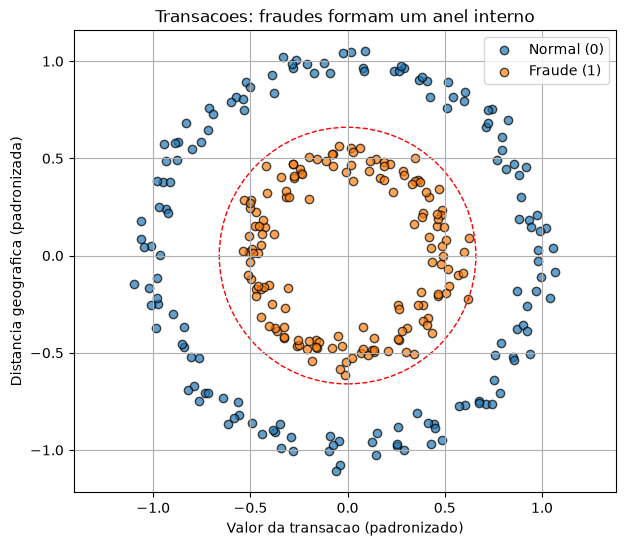

In [12]:
dados = np.genfromtxt("dataset_fraude.csv", delimiter=",", skip_header=1)
X = dados[:, :2]
y = dados[:, 2].astype(int)
raio = np.linalg.norm(X, axis=1)

print("Formato:", dados.shape, "| classes:", np.unique(y, return_counts=True))
for classe in [0, 1]:
    r = raio[y == classe]
    print(f"Classe {classe}: raio medio {r.mean():.3f}, desvio {r.std():.3f}, "
          f"intervalo [{r.min():.3f}, {r.max():.3f}]")

plt.figure(figsize=(7, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], alpha=0.7, edgecolors="k", label="Normal (0)")
plt.scatter(X[y == 1, 0], X[y == 1, 1], alpha=0.7, edgecolors="k", label="Fraude (1)")
plt.gca().add_patch(plt.Circle((0, 0), 0.66, fill=False, color="red", linestyle="--"))
plt.title("Transacoes: fraudes formam um anel interno")
plt.xlabel("Valor da transacao (padronizado)")
plt.ylabel("Distancia geografica (padronizada)")
plt.axis("equal")
plt.legend()
plt.grid(True)
plt.show()

Epoca   0 | loss 0.5970 | acc 66.67% | val_loss 0.6220 | val_acc 58.33%


Epoca  50 | loss 0.0004 | acc 100.00% | val_loss 0.0006 | val_acc 100.00%


Epoca 100 | loss 0.0001 | acc 100.00% | val_loss 0.0002 | val_acc 100.00%


Epoca 150 | loss 0.0000 | acc 100.00% | val_loss 0.0001 | val_acc 100.00%


Epoca 199 | loss 0.0000 | acc 100.00% | val_loss 0.0000 | val_acc 100.00%

Acuracia final treino: 100.00%
Acuracia final teste:  100.00%


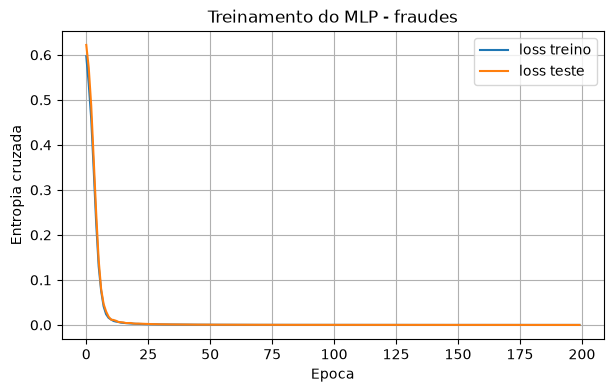

In [13]:
rng = np.random.default_rng(42)
idx = rng.permutation(len(X))
treino, teste = idx[:240], idx[240:]
X_treino, y_treino = X[treino], y[treino]
X_teste, y_teste = X[teste], y[teste]

mlp_fraude = MLPClassifier(hidden_layers=[16, 16], activation="relu",
                           learning_rate=0.01, epochs=200, batch_size=32,
                           random_state=42)
mlp_fraude.fit(X_treino, y_treino, X_teste, y_teste)

print("\nAcuracia final treino: {:.2f}%".format(mlp_fraude.history["acc"][-1] * 100))
print("Acuracia final teste:  {:.2f}%".format(mlp_fraude.evaluate(X_teste, y_teste) * 100))

plt.figure(figsize=(7, 4))
plt.plot(mlp_fraude.history["loss"], label="loss treino")
plt.plot(mlp_fraude.history["val_loss"], label="loss teste")
plt.xlabel("Epoca")
plt.ylabel("Entropia cruzada")
plt.title("Treinamento do MLP - fraudes")
plt.legend()
plt.grid(True)
plt.show()

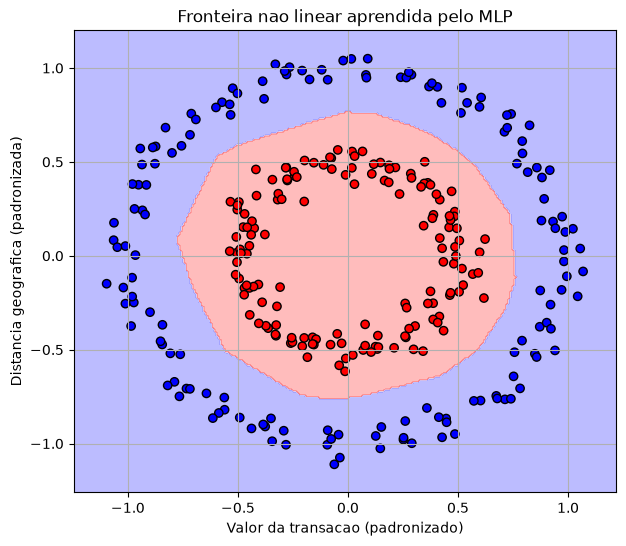

In [14]:
x_min, x_max = X[:, 0].min() - 0.15, X[:, 0].max() + 0.15
y_min, y_max = X[:, 1].min() - 0.15, X[:, 1].max() + 0.15
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
Z = mlp_fraude.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(7, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="bwr")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
plt.xlabel("Valor da transacao (padronizado)")
plt.ylabel("Distancia geografica (padronizada)")
plt.title("Fronteira nao linear aprendida pelo MLP")
plt.grid(True)
plt.show()

### Conclusão — Questão 3

A análise do raio confirma o enunciado: **fraudes têm raio ≈ 0,5** e transações normais **raio ≈ 1,0**. São conjuntos concêntricos, portanto **linearmente inseparáveis** — o Perceptron da Questão 2 falharia aqui.

O MLP com duas camadas ocultas (16 e 16 neurônios, ReLU) aprendeu uma fronteira **circular** e atingiu **100% de acurácia no teste**. A curva de perda caiu rapidamente e estabilizou, sem sinais de overfitting. A arquitetura foi suficiente porque a fronteira é simples, embora não linear.

## Questão 4 — Robô advisor (MLP multiclasse)

Agora há 4 características e **3 classes de risco** (0, 1, 2). O modelo precisa de múltiplas saídas: usamos o mesmo MLP, com **3 neurônios na camada de saída + softmax**, e entropia cruzada (`CrossEntropyLoss`, como na Aula 10). A classe prevista é o índice de maior probabilidade.

In [15]:
dados = np.genfromtxt("dataset_investimentos.csv", delimiter=",", skip_header=1)
X = dados[:, :-1]
y = dados[:, -1].astype(int)

print("Formato:", dados.shape)
print("Classes (0=Baixo, 1=Medio, 2=Alto):", np.unique(y, return_counts=True))
print("Medias por classe:")
for classe in np.unique(y):
    print(f"  classe {classe}:", np.round(X[y == classe].mean(axis=0), 2))

Formato: (400, 5)
Classes (0=Baixo, 1=Medio, 2=Alto): (array([0, 1, 2]), array([134, 133, 133]))
Medias por classe:
  classe 0: [ 9.21  4.14  9.87 -5.69]
  classe 1: [-2.8   4.98  9.79 -3.63]
  classe 2: [-7.32 -2.34 -3.59 -2.66]


Epoca   0 | loss 0.0284 | acc 100.00% | val_loss 0.0218 | val_acc 100.00%
Epoca  50 | loss 0.0001 | acc 100.00% | val_loss 0.0000 | val_acc 100.00%


Epoca 100 | loss 0.0000 | acc 100.00% | val_loss 0.0000 | val_acc 100.00%
Epoca 150 | loss 0.0000 | acc 100.00% | val_loss 0.0000 | val_acc 100.00%


Epoca 199 | loss 0.0000 | acc 100.00% | val_loss 0.0000 | val_acc 100.00%

Acuracia final treino: 100.00%
Acuracia final teste:  100.00%


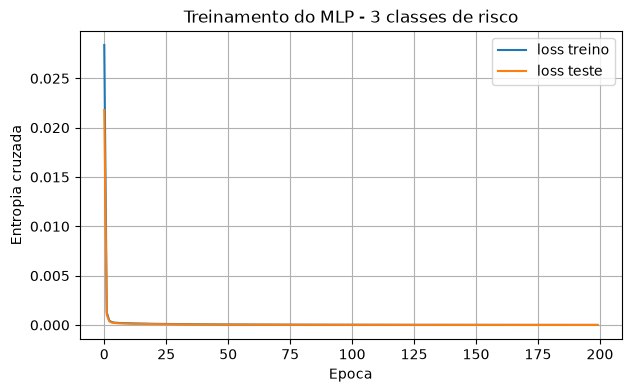

In [16]:
rng = np.random.default_rng(42)
idx = rng.permutation(len(X))
treino, teste = idx[:320], idx[320:]
X_treino, y_treino = X[treino], y[treino]
X_teste, y_teste = X[teste], y[teste]

mlp_risco = MLPClassifier(hidden_layers=[16, 16], activation="relu",
                          learning_rate=0.01, epochs=200, batch_size=32,
                          random_state=42)
mlp_risco.fit(X_treino, y_treino, X_teste, y_teste)

print("\nAcuracia final treino: {:.2f}%".format(mlp_risco.history["acc"][-1] * 100))
print("Acuracia final teste:  {:.2f}%".format(mlp_risco.evaluate(X_teste, y_teste) * 100))

plt.figure(figsize=(7, 4))
plt.plot(mlp_risco.history["loss"], label="loss treino")
plt.plot(mlp_risco.history["val_loss"], label="loss teste")
plt.xlabel("Epoca")
plt.ylabel("Entropia cruzada")
plt.title("Treinamento do MLP - 3 classes de risco")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
y_prev = mlp_risco.predict(X_teste)
matriz = np.zeros((3, 3), dtype=int)
for real, previsto in zip(y_teste, y_prev):
    matriz[real, previsto] += 1

print("Matriz de confusao (linhas = real, colunas = previsto):")
print("        prev 0  prev 1  prev 2")
for i in range(3):
    print(f"real {i}  {matriz[i, 0]:6d}  {matriz[i, 1]:6d}  {matriz[i, 2]:6d}")

print("\nAcuracia por classe:")
for i in range(3):
    print(f"  classe {i}: {matriz[i, i] / matriz[i].sum() * 100:.2f}%")

Matriz de confusao (linhas = real, colunas = previsto):
        prev 0  prev 1  prev 2
real 0      17       0       0
real 1       0      28       0
real 2       0       0      35

Acuracia por classe:
  classe 0: 100.00%
  classe 1: 100.00%
  classe 2: 100.00%


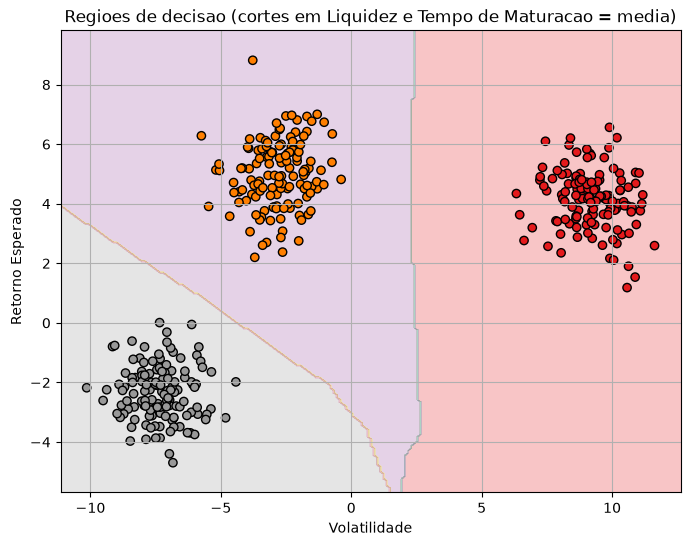

In [18]:
media = X.mean(axis=0)
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grade = np.c_[xx.ravel(), yy.ravel(),
              np.full(xx.size, media[2]), np.full(xx.size, media[3])]
Z = mlp_risco.predict(grade).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="Set1")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="Set1", edgecolors="k")
plt.xlabel("Volatilidade")
plt.ylabel("Retorno Esperado")
plt.title("Regioes de decisao (cortes em Liquidez e Tempo de Maturacao = media)")
plt.grid(True)
plt.show()

### Conclusão — Questão 4

As três classes ocupam regiões bem distintas no espaço de 4 dimensões (médias muito separadas e desvio ≈ 1), o que explica a convergência rápida e a **acurácia de 100% no teste**, com matriz de confusão diagonal.

O ponto importante é a **saída multiclasse**: 3 neurônios, softmax e escolha do maior valor. Isso generaliza o caso binário da Questão 3 (2 saídas) e atende ao pedido do enunciado de "suportar múltiplas saídas". O robô advisor recebe Volatilidade, Retorno, Liquidez e Tempo de Maturação e devolve o nível de risco (0 = baixo, 1 = médio, 2 = alto).

## Resumo final

| Questão | Modelo | Resultado no teste |
| --- | --- | --- |
| 1 — Marketing | K-means (k = 3) | 3 grupos de 100 clientes, joelho da inércia em k = 3 |
| 2 — Crédito | Perceptron (pocket + z-score) | ~86% de acurácia (dados com sobreposição) |
| 3 — Fraude | MLP 2 camadas ocultas | 100% de acurácia, fronteira circular |
| 4 — Investimentos | MLP 2 camadas ocultas, 3 saídas | 100% de acurácia, classes bem separadas |

Todos os modelos foram implementados com **NumPy + matplotlib**, sem scikit-learn, pandas ou TensorFlow/Keras.